1.Importações e Configurações

In [ ]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.metrics import (
    recall_score, precision_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report
)
from xgboost import XGBClassifier

# Reprodutibilidade e silenciamento de logs verbosos do Optuna
RANDOM_STATE = 42
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

2. Carregamento dos Dados e do Template

In [ ]:
DATA_DIR = Path("../data/processed")
if not DATA_DIR.exists():
    DATA_DIR = Path("data/processed")

DTYPES = {
    "id_cliente": "string",
    "tipo_contrato": "string",
    "forma_pagamento": "string",
}

df_treino = pd.read_csv(DATA_DIR / "treino_antes_imputacao.csv", dtype=DTYPES)
df_teste = pd.read_csv(DATA_DIR / "teste_antes_imputacao.csv", dtype=DTYPES)
preprocessador_template = joblib.load(DATA_DIR / "preprocessador_template.joblib")

X_treino = df_treino.drop(columns=["id_cliente", "churn"])
y_treino = df_treino["churn"].astype(int)

X_teste = df_teste.drop(columns=["id_cliente", "churn"])
y_teste = df_teste["churn"].astype(int)

# Validação cruzada oficial definida no preprocessing.ipynb
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Razão de desbalanceamento no treino (negativos / positivos ≈ 1.82)
razao_classes = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f"Treino: {X_treino.shape} | Teste: {X_teste.shape}")
print(f"Proporção Negativos/Positivos no treino: {razao_classes:.2f}")

Treino: (3493, 8) | Teste: (1497, 8)
Proporção Negativos/Positivos no treino: 1.82


3.Modelo Baseline (Sem Tunagem)

In [ ]:
pipeline_baseline = Pipeline([
    ("preprocessador", clone(preprocessador_template)),
    ("modelo", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

metricas = ["recall", "precision", "f1", "roc_auc"]
res_base = cross_validate(pipeline_baseline, X_treino, y_treino, cv=cv, scoring=metricas, n_jobs=1)

print("--- BASELINE XGBOOST (Validação Cruzada 5-Fold) ---")
for m in metricas:
    print(f"{m.upper():10s}: {res_base[f'test_{m}'].mean():.4f} ± {res_base[f'test_{m}'].std():.4f}")

--- BASELINE XGBOOST (Validação Cruzada 5-Fold) ---
RECALL    : 0.5298 ± 0.0162
PRECISION : 0.5833 ± 0.0276
F1        : 0.5551 ± 0.0189
ROC_AUC   : 0.7486 ± 0.0144


4. Otimização Bayesiana com Optuna (Foco em Recall)

In [ ]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0),
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    pipeline = Pipeline([
        ("preprocessador", clone(preprocessador_template)),
        ("modelo", XGBClassifier(**params))
    ])

    scores = cross_validate(pipeline, X_treino, y_treino, cv=cv, scoring="recall", n_jobs=1)
    return scores["test_score"].mean()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
)
study.optimize(objective, n_trials=60, show_progress_bar=True)

print(f"\nMelhor Recall (CV): {study.best_value:.4f}")
print("Melhores hiperparâmetros:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

  0%|          | 0/60 [00:00<?, ?it/s]


Melhor Recall (CV): 0.8976
Melhores hiperparâmetros:
  n_estimators: 214
  learning_rate: 0.012916943381414525
  max_depth: 2
  subsample: 0.9400090714113671
  colsample_bytree: 0.5315400482995369
  gamma: 4.509725281469893
  reg_alpha: 7.754494341055396e-06
  reg_lambda: 1.8341863717650742e-07
  scale_pos_weight: 2.932200966656353


5. Trade-off n_estimators vs learning_rate

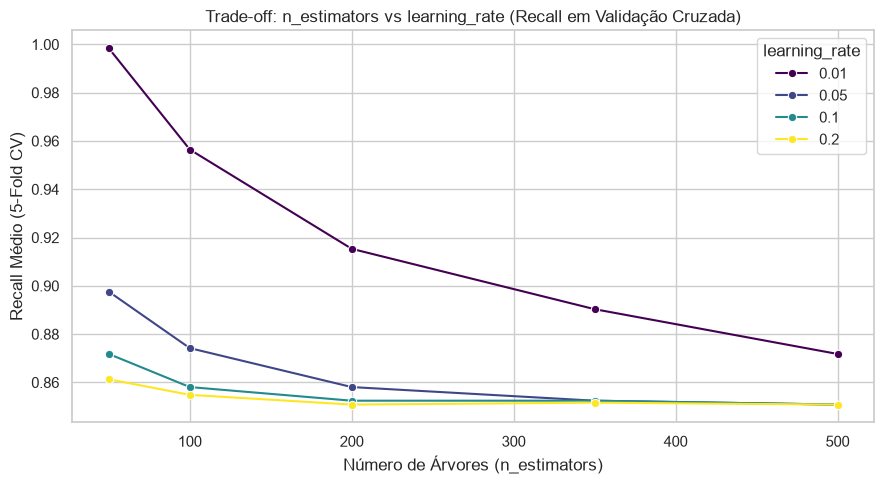

In [ ]:
# Fixa os melhores hiperparâmetros do Optuna e varia apenas n_estimators e learning_rate
taxas = [0.01, 0.05, 0.1, 0.2]
arvores = [50, 100, 200, 350, 500]
resultados_tradeoff = []

params_base = study.best_params.copy()
for lr in taxas:
    for n_est in arvores:
        p = {**params_base, "learning_rate": lr, "n_estimators": n_est,
             "objective": "binary:logistic", "eval_metric": "logloss",
             "random_state": RANDOM_STATE, "n_jobs": -1}
        pipe = Pipeline([
            ("preprocessador", clone(preprocessador_template)),
            ("modelo", XGBClassifier(**p))
        ])
        sc = cross_validate(pipe, X_treino, y_treino, cv=cv, scoring="recall", n_jobs=1)
        resultados_tradeoff.append({
            "learning_rate": lr,
            "n_estimators": n_est,
            "recall_cv": sc["test_score"].mean()
        })

df_tradeoff = pd.DataFrame(resultados_tradeoff)
plt.figure(figsize=(9, 5))
sns.lineplot(data=df_tradeoff, x="n_estimators", y="recall_cv", hue="learning_rate", marker="o", palette="viridis")
plt.title("Trade-off: n_estimators vs learning_rate (Recall em Validação Cruzada)")
plt.ylabel("Recall Médio (5-Fold CV)")
plt.xlabel("Número de Árvores (n_estimators)")
plt.legend(title="learning_rate")
plt.tight_layout()
plt.show()

6. Curva de Aprendizado (Análise de Overfitting)

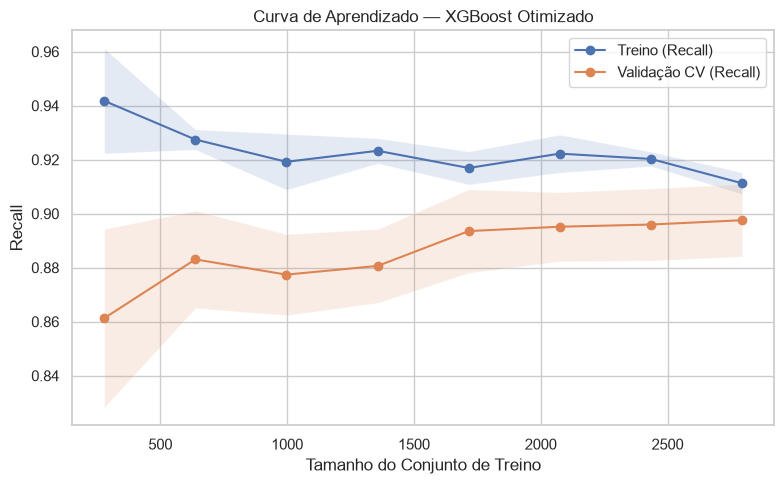

In [ ]:
melhores_params = {
    **study.best_params,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

pipeline_final = Pipeline([
    ("preprocessador", clone(preprocessador_template)),
    ("modelo", XGBClassifier(**melhores_params))
])

train_sizes, train_scores, val_scores = learning_curve(
    pipeline_final, X_treino, y_treino,
    cv=cv, scoring="recall", n_jobs=1,
    train_sizes=np.linspace(0.1, 1.0, 8)
)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Treino (Recall)")
plt.plot(train_sizes, val_scores.mean(axis=1), "o-", label="Validação CV (Recall)")
plt.fill_between(train_sizes, train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15)
plt.fill_between(train_sizes, val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
plt.title("Curva de Aprendizado — XGBoost Otimizado")
plt.xlabel("Tamanho do Conjunto de Treino")
plt.ylabel("Recall")
plt.legend()
plt.tight_layout()
plt.show()

7. Treino Final e Avaliação Cega no Teste

--- AVALIAÇÃO FINAL (TESTE 30%) ---
Recall Treino : 0.9137
Recall Teste  : 0.8872
Gap Overfit   : 0.0265

Precision     : 0.4816
F1-Score      : 0.6243
ROC-AUC       : 0.7803

               precision    recall  f1-score   support

Não-Churn (0)       0.88      0.47      0.62       965
    Churn (1)       0.48      0.89      0.62       532

     accuracy                           0.62      1497
    macro avg       0.68      0.68      0.62      1497
 weighted avg       0.74      0.62      0.62      1497



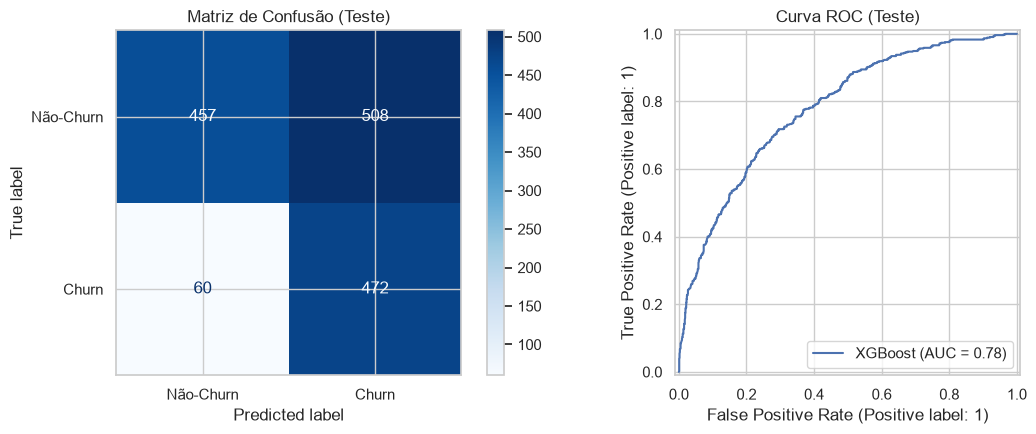

In [ ]:
# Ajuste único no treino completo (70%) e avaliação no teste reservado (30%)
pipeline_final.fit(X_treino, y_treino)

y_pred_treino = pipeline_final.predict(X_treino)
y_pred_teste = pipeline_final.predict(X_teste)
y_proba_teste = pipeline_final.predict_proba(X_teste)[:, 1]

recall_tr = recall_score(y_treino, y_pred_treino)
recall_te = recall_score(y_teste, y_pred_teste)

print("--- AVALIAÇÃO FINAL (TESTE 30%) ---")
print(f"Recall Treino : {recall_tr:.4f}")
print(f"Recall Teste  : {recall_te:.4f}")
print(f"Gap Overfit   : {recall_tr - recall_te:.4f}\n")
print(f"Precision     : {precision_score(y_teste, y_pred_teste):.4f}")
print(f"F1-Score      : {f1_score(y_teste, y_pred_teste):.4f}")
print(f"ROC-AUC       : {roc_auc_score(y_teste, y_proba_teste):.4f}\n")
print(classification_report(y_teste, y_pred_teste, target_names=["Não-Churn (0)", "Churn (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_teste, y_pred_teste), display_labels=["Não-Churn", "Churn"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Matriz de Confusão (Teste)")

RocCurveDisplay.from_predictions(y_teste, y_proba_teste, ax=axes[1], name="XGBoost")
axes[1].set_title("Curva ROC (Teste)")
plt.tight_layout()
plt.show()

8. Feature Importance (Nativa + SHAP)

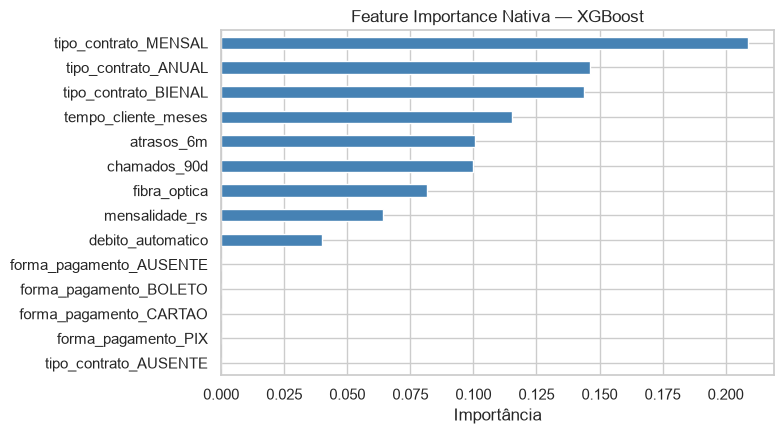

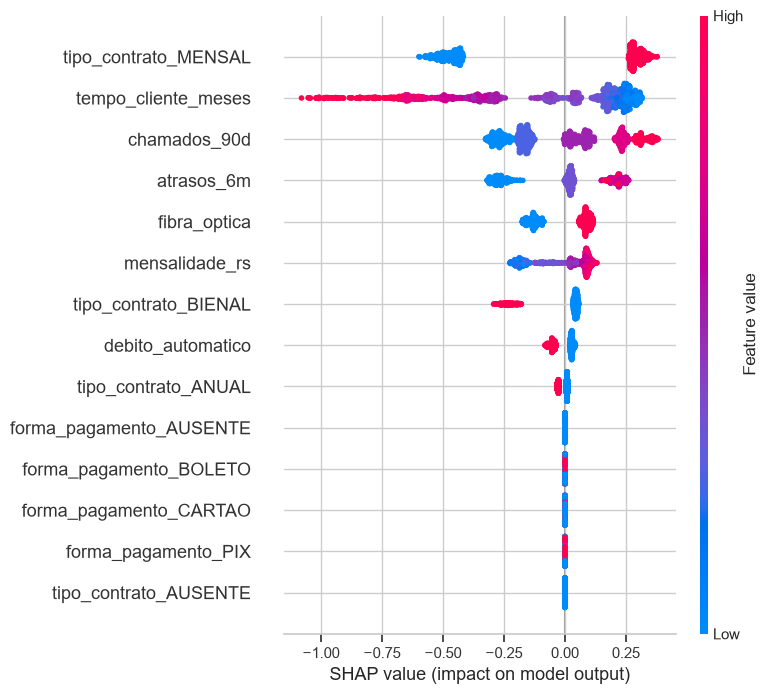

In [ ]:
prep_ajustado = pipeline_final.named_steps["preprocessador"]
xgb_ajustado = pipeline_final.named_steps["modelo"]

X_teste_proc = prep_ajustado.transform(X_teste)

# 1. Importância nativa do XGBoost
importancias = pd.Series(xgb_ajustado.feature_importances_, index=X_teste_proc.columns).sort_values()
plt.figure(figsize=(8, 4.5))
importancias.plot(kind="barh", color="steelblue")
plt.title("Feature Importance Nativa — XGBoost")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

# 2. Análise SHAP (explicabilidade direcional)
explainer = shap.TreeExplainer(xgb_ajustado)
shap_values = explainer.shap_values(X_teste_proc)
shap.summary_plot(shap_values, X_teste_proc)

9. Curva de Erro (Logloss: Treino vs. Teste) e a Curva Precision-Recall:

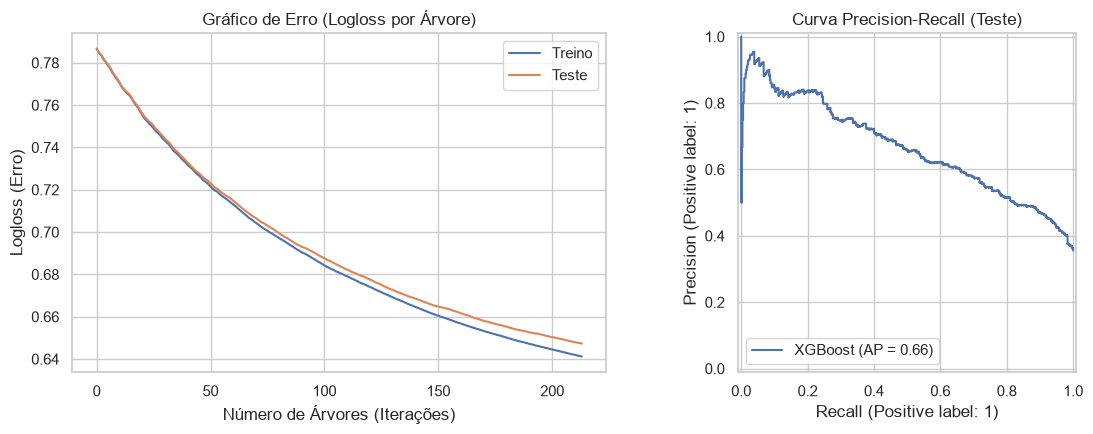

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay

# 1. Gráfico de Erro (Logloss por iteração do XGBoost)
X_tr_proc = prep_ajustado.transform(X_treino)
X_te_proc = prep_ajustado.transform(X_teste)

xgb_eval = XGBClassifier(**melhores_params)
xgb_eval.fit(
    X_tr_proc, y_treino,
    eval_set=[(X_tr_proc, y_treino), (X_te_proc, y_teste)],
    verbose=False
)
resultados_erro = xgb_eval.evals_result()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(resultados_erro["validation_0"]["logloss"], label="Treino")
axes[0].plot(resultados_erro["validation_1"]["logloss"], label="Teste")
axes[0].set_title("Gráfico de Erro (Logloss por Árvore)")
axes[0].set_xlabel("Número de Árvores (Iterações)")
axes[0].set_ylabel("Logloss (Erro)")
axes[0].legend()

# 2. Curva Precision-Recall (excelente para justificar o trade-off de Churn)
PrecisionRecallDisplay.from_predictions(y_teste, y_proba_teste, ax=axes[1], name="XGBoost")
axes[1].set_title("Curva Precision-Recall (Teste)")

plt.tight_layout()
plt.show()